# When does a gamma ray give up all its energy in one step?
### Photoelectric share of photon interactions in NaI(Tl), CZT, CsPbBr₃ and HPGe – from NIST XCOM

This notebook reproduces **Figure 1** of the PV Sensors article
[*How a gamma-ray detector works – from one photon to becquerels*](https://pvsensors.com/blog/detectors/how-a-gamma-ray-detector-works).

For every photon energy it computes which fraction of the interactions that **deposit energy** in the detector is
**photoelectric absorption** (the one we want for spectroscopy: one interaction, all the energy, one count in the full-energy peak):

$$
f_\mathrm{photo}(E) = \frac{\tau(E)}{\tau(E) + \sigma_\mathrm{incoh}(E) + \kappa(E)}
$$

with τ the photoelectric, σ<sub>incoh</sub> the incoherent (Compton) and κ the pair-production mass attenuation coefficients.
Coherent (Rayleigh) scattering is left out because it deposits no energy.

**All cross-sections come from NIST XCOM** – M. J. Berger, J. H. Hubbell, S. M. Seltzer *et al.*,
*XCOM: Photon Cross Sections Database*, NIST Standard Reference Database 8,
[doi:10.18434/T48G6X](https://doi.org/10.18434/T48G6X).

| Section | What it does |
|---|---|
| 1 | Setup |
| 2 | Where the data come from – and how to download them yourself (web form or code) |
| 3 | Load the XCOM element tables |
| 4 | Build the detector materials with the mixture rule |
| 5 | Photoelectric share and crossover energies |
| 6 | Plot Figure 1 and save it as PNG / SVG |
| 7 | Optional checks against XCOM's own compound calculation |

## 1. Setup

```bash
git clone https://github.com/PVSensors/how-a-gamma-ray-detector-works.git
cd how-a-gamma-ray-detector-works
python -m venv .venv && source .venv/bin/activate      # Windows: .venv\Scripts\activate
pip install -r requirements.txt
jupyter lab figure1_photoelectric_share.ipynb
```

Then run all cells (**Run → Run All Cells**). Without internet the notebook uses the cached XCOM tables in
`data/xcom_elements.json`; set `FETCH_FROM_NIST = True` in section 2 to download fresh tables from NIST.

In [1]:
import json, math, re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

DATA = Path("data/xcom_elements.json")
print("numpy", np.__version__)

numpy 2.5.3


## 2. Where the data come from

### 2a. By hand, with the XCOM web form
1. Open <https://physics.nist.gov/PhysRefData/Xcom/html/xcom1.html>.
2. Choose **Element**, type the symbol (for example `Ge`) and press **Submit Information**.
3. On the next page, untick *Standard grid* if you only want your own energies, and paste your energies (in **MeV**,
   one per line or separated by `;`) into **Additional energies**. XCOM accepts only a limited number of energies per
   request – about 60 works.
4. Select the output in **cm²/g** and **Submit Information**. The table gives, for every energy:
   coherent, incoherent, photoelectric, pair production (nuclear and electron field) and total attenuation.
5. Repeat for every element. For compounds you can also use **Compound** (formula, e.g. `CsPbBr3`) or **Mixture**
   (lines like `Cd 0.4` with mass fractions) – section 7 checks that our mixture rule gives the same numbers.

### 2b. With code
The function below sends exactly the same request as the web form (`xcom3_1` = element, `xcom3_3` = mixture) and
parses the HTML table. It needs `requests` and internet access.

In [2]:
XCOM_COLUMNS = ["coherent", "incoherent", "photoelectric", "pair_nuclear", "pair_electron",
                "total_with_coherent", "total_without_coherent"]

def _parse_xcom_table(html):
    """Rows of the XCOM output table: [edge, energy (MeV), 7 cross-sections in cm²/g]."""
    from html.parser import HTMLParser
    class Rows(HTMLParser):
        def __init__(self):
            super().__init__(); self.rows, self.row, self.cell, self.td = [], [], "", False
        def handle_starttag(self, tag, attrs):
            if tag == "tr": self.row = []
            if tag == "td": self.td, self.cell = True, ""
        def handle_endtag(self, tag):
            if tag == "td": self.td = False; self.row.append(self.cell.strip())
            if tag == "tr" and len(self.row) == 9 and "E" in self.row[1]: self.rows.append(self.row)
        def handle_data(self, d):
            if self.td: self.cell += d
    p = Rows(); p.feed(html)
    return p.rows

def fetch_xcom(symbol=None, mixture=None, energies_kev=(), chunk=60):
    """Query NIST XCOM for one element (symbol='Ge') or a mixture (mixture=['Cd 0.4', 'Te 0.6'])
    at the given energies (keV). Returns {column: [values in cm²/g]}."""
    import requests
    url = "https://physics.nist.gov/cgi-bin/Xcom/xcom3_" + ("1" if symbol else "3")
    rows = []
    energies_kev = list(energies_kev)
    for i in range(0, len(energies_kev), chunk):
        data = {"NumAdd": "1", "WindowXmin": "0.001", "WindowXmax": "100", "OutOpt": "PIC", "ResizeFlag": "on",
                "Energies": ";".join(f"{e / 1000:.6f}" for e in energies_kev[i:i + chunk])}
        if symbol: data["ZSym"] = symbol
        else: data["Formulae"] = "\r\n".join(mixture)
        r = requests.post(url, data=data, timeout=60)
        r.raise_for_status()
        if "Error" in r.text:
            raise RuntimeError("XCOM error: " + re.sub("<[^>]+>", " ", r.text)[:300])
        rows += _parse_xcom_table(r.text)
    return {c: [float(row[k + 2]) for row in rows] for k, c in enumerate(XCOM_COLUMNS)}

**Energy grid.** 179 energies from 10 keV to 3 MeV: 130 log-spaced points, the gamma lines we care about
(59.54, 122.06, 140.5, 511, 661.66, 1173.2, 1332.5 keV) and two points 0.05 keV below and above every K and L
absorption edge of the elements (so that the edges are sharp). The cached file was downloaded with the cell below on
25 Nov 2026.

In [3]:
FETCH_FROM_NIST = False   # True: download fresh tables from NIST (internet needed, ~1 min)

ELEMENTS = ["H", "C", "N", "O", "Na", "Si", "S", "Zn", "Ge", "Se", "Br", "Y",
            "Cd", "Te", "I", "Cs", "La", "Gd", "Lu", "Pb", "Bi"]

if FETCH_FROM_NIST:
    X = json.loads(DATA.read_text())          # reuse the energy grid of the cached file
    for el in ELEMENTS:
        X["elements"][el] = fetch_xcom(symbol=el, energies_kev=X["energy_keV"])
        print("fetched", el)
    DATA.write_text(json.dumps(X))

## 3. Load the XCOM element tables

In [4]:
X = json.loads(DATA.read_text())
E = np.array(X["energy_keV"])                       # keV
print(X["source"])
print(f"{len(E)} energies from {E[0]:g} to {E[-1]:g} keV; elements:", ", ".join(X["elements"]))

# example: germanium at 662 keV
i = np.argmin(abs(E - 661.66))
print({c: X["elements"]["Ge"][c][i] for c in XCOM_COLUMNS}, "cm²/g at", E[i], "keV")

NIST XCOM (NIST Standard Reference Database 8), https://physics.nist.gov/PhysRefData/Xcom/html/xcom1.html, doi:10.18434/T48G6X; queried element by element (xcom3_1) on 2026-11-25
179 energies from 10 to 3000 keV; elements: Ge, H, C, N, O, Na, Si, S, Zn, Se, Br, Y, Cd, Te, I, Cs, La, Gd, Lu, Pb, Bi
{'coherent': 0.001364, 'incoherent': 0.06771, 'photoelectric': 0.001763, 'pair_nuclear': 0, 'pair_electron': 0, 'total_with_coherent': 0.07083, 'total_without_coherent': 0.06947} cm²/g at 661.66 keV


## 4. Detector materials – the mixture rule

For a compound, XCOM adds the elemental mass attenuation coefficients weighted by mass fraction w<sub>i</sub>:

$$ (\mu/\rho)_\mathrm{compound} = \sum_i w_i\,(\mu/\rho)_i $$

The mass fractions come from the chemical formula and the standard atomic weights.

In [5]:
ATOMIC_WEIGHT = {"H": 1.008, "C": 12.011, "N": 14.007, "O": 15.999, "Na": 22.990, "Si": 28.085, "S": 32.06,
                 "Zn": 65.38, "Ge": 72.630, "Se": 78.971, "Br": 79.904, "Y": 88.906, "Cd": 112.41, "Te": 127.60,
                 "I": 126.90, "Cs": 132.91, "La": 138.91, "Gd": 157.25, "Lu": 174.97, "Pb": 207.2, "Bi": 208.98}

def mass_fractions(formula):
    parts = re.findall(r"([A-Z][a-z]?)([0-9.]*)", formula)
    m = [(el, (float(n) if n else 1.0) * ATOMIC_WEIGHT[el]) for el, n in parts]
    tot = sum(x for _, x in m)
    w = {}
    for el, x in m:
        w[el] = w.get(el, 0.0) + x / tot
    return w

def compound(formula, column):
    return sum(w * np.array(X["elements"][el][column]) for el, w in mass_fractions(formula).items())

# the four materials of Figure 1: key -> (label, formula, role, colour)
MATERIALS = {
    "nai":     ("NaI(Tl)",      "NaI",          "scintillator",          "#5856d6"),
    "czt":     ("CdZnTe (CZT)", "Cd0.9Zn0.1Te", "semiconductor",         "#00918a"),
    "cspbbr3": ("CsPbBr₃",      "CsPbBr3",      "perovskite",            "#e06a1b"),
    "hpge":    ("HPGe",         "Ge",           "semiconductor, cooled", "#172a31"),
}
for k, (label, f, *_ ) in MATERIALS.items():
    print(f"{label:14s}", {el: round(w, 4) for el, w in mass_fractions(f).items()})

NaI(Tl)        {'Na': 0.1534, 'I': 0.8466}
CdZnTe (CZT)   {'Cd': 0.4299, 'Zn': 0.0278, 'Te': 0.5423}
CsPbBr₃        {'Cs': 0.2292, 'Pb': 0.3574, 'Br': 0.4134}
HPGe           {'Ge': 1.0}


## 5. Photoelectric share and crossover energies

In [6]:
def photo_share(formula):
    tau = compound(formula, "photoelectric")
    sig = compound(formula, "incoherent")
    kap = compound(formula, "pair_nuclear") + compound(formula, "pair_electron")
    return 100 * tau / (tau + sig + kap)

def at(e, y):
    """log-energy interpolation"""
    return float(np.interp(np.log(e), np.log(E), y))

def crossover(y, level=50.0):
    """energy where the share falls through `level` % (log interpolation)"""
    for j in range(1, len(E)):
        if y[j - 1] >= level > y[j]:
            f = (level - y[j - 1]) / (y[j] - y[j - 1])
            return math.exp(math.log(E[j - 1]) + f * (math.log(E[j]) - math.log(E[j - 1])))

SHARE = {k: photo_share(f) for k, (label, f, *_) in MATERIALS.items()}

print(f"{'material':14s} {'50 % crossover':>15s} {'59.5 keV':>9s} {'122 keV':>9s} {'662 keV':>9s} {'1332 keV':>9s}")
for k, (label, *_ ) in MATERIALS.items():
    y = SHARE[k]
    print(f"{label:14s} {crossover(y):12.0f} keV" + "".join(f"{at(e, y):8.1f} %" for e in (59.54, 122.06, 661.66, 1332.5)))

material        50 % crossover  59.5 keV   122 keV   662 keV  1332 keV
NaI(Tl)                 264 keV    98.2 %    88.2 %    11.6 %     4.0 %
CdZnTe (CZT)            263 keV    98.2 %    88.3 %    11.3 %     4.0 %
CsPbBr₃                 363 keV    97.6 %    93.2 %    23.1 %     8.9 %
HPGe                    150 keV    93.5 %    64.1 %     2.5 %     0.8 %


**Reading the numbers.** In germanium the photoelectric effect and the rest are equally likely at about 150 keV;
in NaI(Tl) and CZT at about 265 keV; in CsPbBr₃, thanks to lead (Z = 82), only at about 365 keV. At the ¹³⁷Cs line
(662 keV) about 23 % of the interactions in CsPbBr₃ are photoelectric – twice as many as in NaI(Tl) or CZT and almost
ten times more than in germanium.

## 6. Figure 1

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


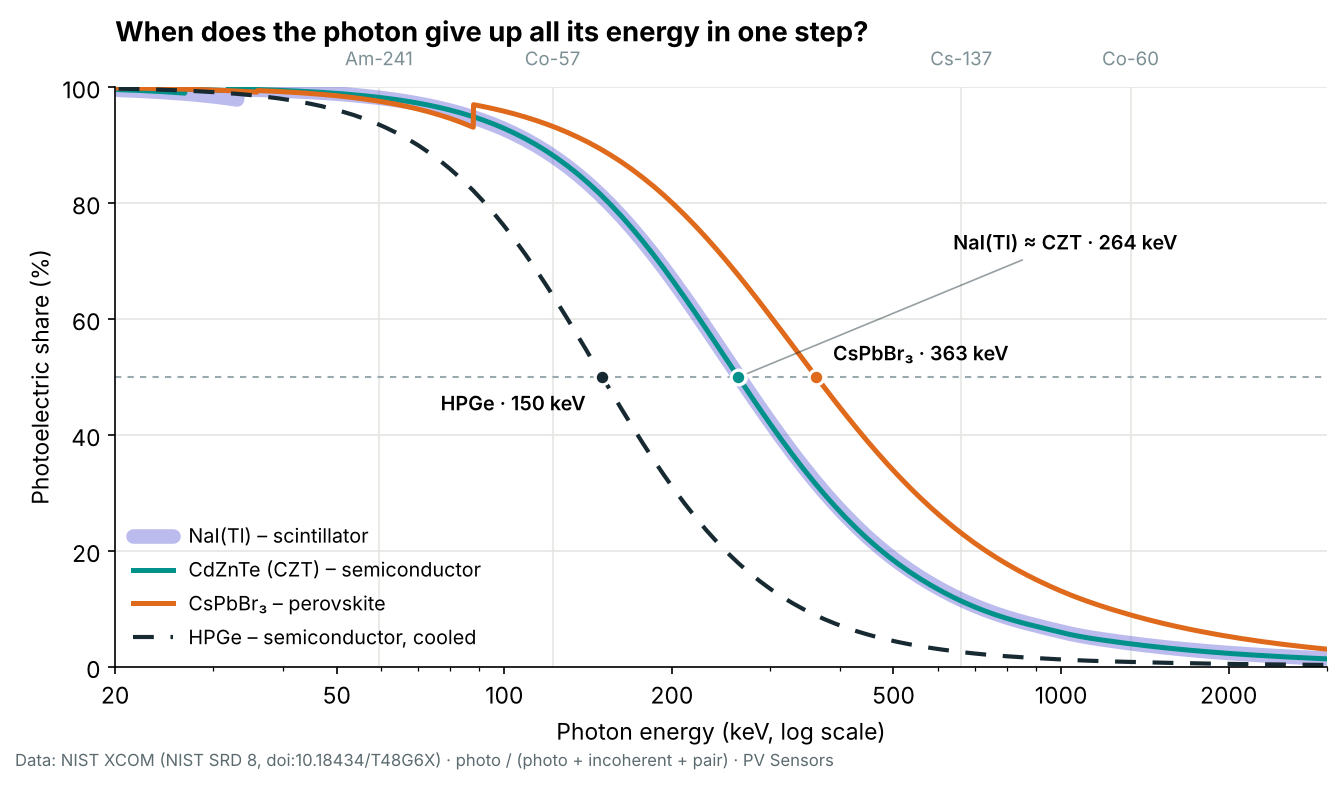

In [7]:
plt.rcParams.update({"font.family": ["Inter", "DejaVu Sans"], "font.size": 11})
fig, ax = plt.subplots(figsize=(9, 5.2), dpi=150)
mask = E >= 20

for k, (label, f, role, color) in MATERIALS.items():
    y = SHARE[k]
    if k == "nai":   # NaI(Tl) and CZT almost coincide: NaI as a wide translucent band under CZT
        ax.plot(E[mask], y[mask], color=color, lw=7, alpha=0.4, solid_capstyle="round", label=f"{label} – {role}")
    elif k == "hpge":
        ax.plot(E[mask], y[mask], color=color, lw=2, ls=(0, (5, 4)), label=f"{label} – {role}")
    else:
        ax.plot(E[mask], y[mask], color=color, lw=2.4, label=f"{label} – {role}")
    ax.plot(crossover(y), 50, "o", ms=7, color=color, mec="white", mew=1.5, alpha=0.6 if k == "nai" else 1, zorder=5)

ax.axhline(50, color="#9aa9ad", lw=1, ls=(0, (3, 3)))
for e, name in [(59.54, "Am-241"), (122.06, "Co-57"), (661.66, "Cs-137"), (1332.5, "Co-60")]:
    ax.axvline(e, color="#e8ebe7", lw=1, zorder=0)
    ax.text(e, 103, name, ha="center", va="bottom", fontsize=9, color="#7c8f94")
ax.annotate(f"HPGe · {crossover(SHARE['hpge']):.0f} keV", (crossover(SHARE['hpge']), 50), (-8, -16), textcoords="offset points", ha="right", fontsize=9.5, weight="semibold")
ax.annotate(f"NaI(Tl) ≈ CZT · {crossover(SHARE['nai']):.0f} keV", (crossover(SHARE['nai']), 50), (640, 72), textcoords="data",
            fontsize=9.5, weight="semibold", arrowprops=dict(arrowstyle="-", color="#172a31", alpha=0.45, lw=0.8))
ax.annotate(f"CsPbBr₃ · {crossover(SHARE['cspbbr3']):.0f} keV", (crossover(SHARE['cspbbr3']), 50), (8, 8), textcoords="offset points", fontsize=9.5, weight="semibold")

ax.set_xscale("log"); ax.set_xlim(20, 3000); ax.set_ylim(0, 100)
ax.set_xticks([20, 50, 100, 200, 500, 1000, 2000]); ax.set_xticklabels(["20", "50", "100", "200", "500", "1000", "2000"])
ax.set_xlabel("Photon energy (keV, log scale)"); ax.set_ylabel("Photoelectric share (%)")
ax.grid(axis="y", color="#e3e6e1"); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left", fontsize=9.5)
ax.set_title("When does the photon give up all its energy in one step?", loc="left", weight="bold", pad=22)
fig.text(0.01, 0.005, "Data: NIST XCOM (NIST SRD 8, doi:10.18434/T48G6X) · photo / (photo + incoherent + pair) · PV Sensors",
         fontsize=8, color="#5b6b70")
fig.tight_layout()
fig.savefig("figure1_photoelectric_share.png", dpi=200)
fig.savefig("figure1_photoelectric_share.svg")
plt.show()

## 7. Optional checks (internet needed)

**a) Mixture rule vs. XCOM's own compound calculation.** XCOM can compute a compound directly; the result must equal
our weighted sum. Set `CHECK = True` to compare CsPbBr₃ and CZT at a few energies.

**b) Your own materials.** Add any formula to `MATERIALS` in section 4 (all its elements must be in
`data/xcom_elements.json`, otherwise download them with `fetch_xcom(symbol=...)`) and re-run sections 5–6.

In [8]:
CHECK = False

if CHECK:
    test_e = [59.54, 122.06, 661.66, 1332.5]
    for label, f in [("CsPbBr3", "CsPbBr3"), ("CZT", "Cd0.9Zn0.1Te")]:
        mix = [f"{el} {w:.6f}" for el, w in mass_fractions(f).items()]
        ref = fetch_xcom(mixture=mix, energies_kev=test_e)["total_with_coherent"]
        ours = [at(e, compound(f, "total_with_coherent")) for e in test_e]
        for e, a, b in zip(test_e, ours, ref):
            print(f"{label:8s} {e:8.2f} keV  mixture rule {a:.4g}  XCOM {b:.4g}  ({(a / b - 1) * 100:+.2f} %)")

---
**Citation for the data:** M. J. Berger, J. H. Hubbell, S. M. Seltzer, J. Chang, J. S. Coursey, R. Sukumar,
D. S. Zucker and K. Olsen, *XCOM: Photon Cross Sections Database* (version 1.5), NIST Standard Reference Database 8,
National Institute of Standards and Technology, [doi:10.18434/T48G6X](https://doi.org/10.18434/T48G6X).

**Further reading:** G. F. Knoll, *Radiation Detection and Measurement*, 4th ed. (Wiley, 2010), ch. 2 and Fig. 2.20;
G. R. Gilmore, *Practical Gamma-ray Spectrometry*, 2nd ed. (Wiley, 2008), ch. 2.

© PV Sensors – <https://pvsensors.com>